# Project Deliverable #1

Nebraska Tractor Tests (Dataset on Brightspace)

Description: Explore the impacts of draft, and Power Take-Off (PTO) for
different types of tractors for various models and years. Using this dataset will
require that you look up and learn more about the different tractor models, in
order to ask reasonable research questions.

In [15]:
import pandas as pd
import numpy as np

df = pd.read_excel('../Data/12_Nebraska_Tractor_Tests_data.xlsx')

## A detailed dataset description

 1. Meta-data: Include key information like file formats, structure, data types (e.g. tabular, image) measurement formats (e.g. categorical, numeric) units, granularity, dimensions, and any temporal or geographic details.
 2. Variables: Identify and describe response and explanatory variables for each research question


In [8]:
df

,Id,Pdf Link,Year,Nebraska Test Number,Nebraska Summary Number,Manufacturer,Make,Model,Transmission,Chassis,Fuel,PTO HP,Belt HP,Drawbar HP,Remarks
0,1,Click for test report,1920,1,NaN,Waterloo Gas Engine Co.,Waterloo Boy,"N, 12-25",MAN,2WD,K,NaN,25.0,15.0,NaN
1,2,Click for test report,1920,2,NaN,NaN,Withdrawn,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Click for test report,1920,3,NaN,J.I. Case,Case,10-18,MAN,2WD,K,NaN,18.0,11.0,NaN
3,4,Click for test report,1920,4,NaN,J.I. Case,Case,15-27,MAN,2WD,K,NaN,31.0,21.0,NaN
4,5,Click for test report,1920,5,NaN,J.I. Case,Case,22-40,MAN,2WD,K,NaN,49.0,31.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3841,3842,Click for test report,2022,2257,S1220,John Deere,John Deere,5125M,PRPS 4,FWA,D,109.0,NaN,100.0,NaN
3842,3843,Click for test report,2022,2258,S1221,John Deere,John Deere,9R 390,PSH,4WD,D,323.0,NaN,296.0,NaN
3843,3844,Click for test report,2022,2259,S1222,John Deere,John Deere,9R 440,PSH,4WD,D,321.0,NaN,340.0,partial power PTO
3844,3845,Click for test report,2022,2260,S1223,John Deere,John Deere,9R 490,PSH,4WD,D,321.0,NaN,382.0,partial power PTO


In [7]:
df.dtypes

Id                           int64
Pdf Link                    object
Year                         int64
Nebraska Test Number        object
Nebraska Summary Number     object
Manufacturer                object
Make                        object
Model                       object
Transmission                object
Chassis                     object
Fuel                        object
PTO HP                     float64
Belt HP                    float64
Drawbar HP                 float64
Remarks                     object
dtype: object

In [10]:
df['Pdf Link'].unique()

array(['Click for test report'], dtype=object)

In [12]:
df['Nebraska Test Number'].unique()

array(['1', '2', '3', ..., '2259', '2260', '2261'],
      shape=(2356,), dtype=object)

In [22]:
np.where(df['Nebraska Test Number'].str[:7]=='Special')

(array([89]),)

In [27]:
df[89:90]

,Id,Pdf Link,Year,Nebraska Test Number,Nebraska Summary Number,Manufacturer,Make,Model,Transmission,Chassis,Fuel,PTO HP,Belt HP,Drawbar HP,Remarks
89,90,Click for test report,1921,Special A,NaN,Shaw-Enochs,Shawnee,POWER PATROL,MAN,2WD,G,NaN,NaN,7.0,"Tested no Enochs Shawnee 685, no PTO"


In [29]:
len(df['Remarks'].unique())

653

In [36]:
len(df['Nebraska Summary Number'].unique())	

1326

In [35]:
df['Fuel'].value_counts(dropna=False,normalize=True)

Fuel
D       0.765211
G       0.143266
K       0.028861
LPG     0.026781
DIST    0.020021
NaN     0.010920
TF      0.004940
Name: proportion, dtype: float64

In [37]:
len(df['Make'].unique())

143

In [38]:
len(df['Model'].unique())

2484

In [39]:
len(df['Transmission'].unique())

18

In [40]:
len(df['Chassis'].unique())

10

In [41]:
df['Chassis'].value_counts(dropna=False,normalize=True)

Chassis
2WD             0.438638
FWA             0.381175
Crawler         0.079563
4WD             0.078263
NaN             0.010920
4TD             0.007280
half track      0.001560
See Remarks     0.001300
FTA             0.001040
Single Wheel    0.000260
Name: proportion, dtype: float64

In [11]:
df.describe()

,Id,Year,PTO HP,Belt HP,Drawbar HP
count,3846.000000,3846.000000,2953.000000,752.000000,3633.000000
mean,1923.500000,1981.868175,128.743312,40.240691,101.293614
std,1110.388896,26.641834,93.554361,20.497846,88.677504
min,1.000000,1920.000000,11.000000,1.000000,0.600000
25%,962.250000,1962.000000,63.000000,27.000000,41.000000
50%,1923.500000,1984.000000,99.000000,36.000000,71.000000
75%,2884.750000,2005.000000,164.000000,49.000000,131.000000
max,3846.000000,2022.000000,598.000000,145.000000,531.000000


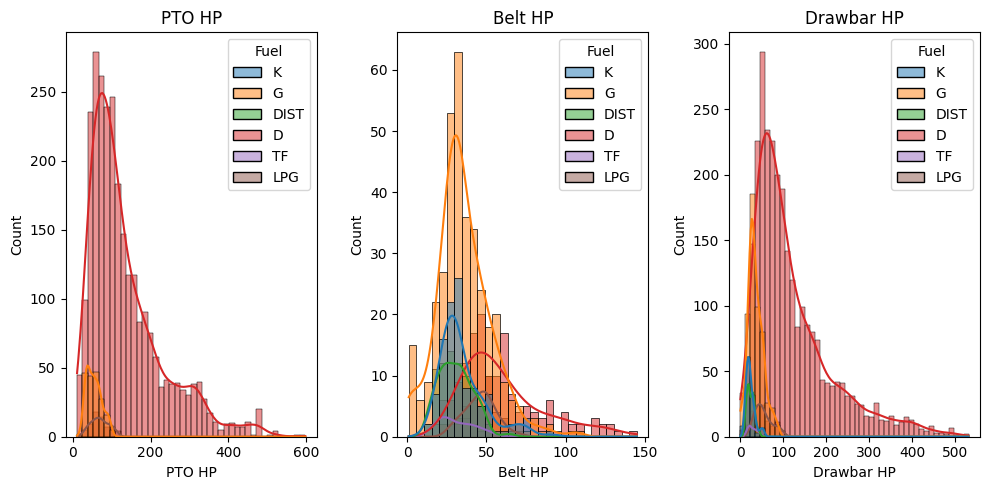

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a figure with a 1x2 grid of subplots
fig, axes = plt.subplots(1, 3, figsize=(10, 5))

# Plot on the first subplot (axes[0])
sns.histplot(x="PTO HP", data=df, ax=axes[0], hue='Fuel', kde=True)
axes[0].set_title('PTO HP')

# Plot on the second subplot (axes[1])
sns.histplot(x="Belt HP", data=df, ax=axes[1], hue='Fuel', kde=True)
axes[1].set_title('Belt HP')

# Plot on the second subplot (axes[1])
sns.histplot(x="Drawbar HP", data=df, ax=axes[2], hue='Fuel', kde=True)
axes[2].set_title('Drawbar HP')

plt.tight_layout() # Adjust layout to prevent overlapping
plt.show()

The dataset is compose of 3 variables related to Horse Power:

- PTO HP: Horsepower Power Take Off - type float
- Belt HP: the power transmitted by a V-belt from a driving pulley to a driven pulley - type float
- Drawbar HP: the usable power available at the drawbar or rear of a tractor, or a locomotive, to pull a load or implement - type float

## Three research questions you have about the data

Hint: For each question, try to identify the explanatory variable(s) (the predictors) and the response variable (the outcome you’re trying to explain). This step is important because clearly linking predictors and outcomes helps you choose the right statistical methods later and ensures your questions can actually be answered with the data available.

Based on the review of the data, i have selected that the most interesting feature to predict is Drawbar HP, based on the PTO HP, Belt HP, the kind of Gear, fuel, transmission and chasis. With this information the 3 questions I would like to answer with the data are the following:


1. Considering a fixed kind of fuel, which are the most important variables to predict the amount of Drawbar HP?

2. Are there any temporal pattern in the evolution of the Drawbar HP?

3. Are there any other confounding variables that might predict the amount of Drawbar HP? Consider analysing the brand and model, to see if there is a certain bias, based on the manufacturer. 